In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

MODEL_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "model_dataset.csv"

MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
RESULTS_FIGURES_DIR = PROJECT_ROOT / "results" / "figures"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_METRICS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Файл с обучающим датасетом:", MODEL_DATA_PATH)
print("Файл существует:", MODEL_DATA_PATH.exists())

Файл с обучающим датасетом: c:\Diplom_Suslikov_2026\diabetes-risk-stratifier\data\processed\model_dataset.csv
Файл существует: True


In [3]:
model_df = pd.read_csv(MODEL_DATA_PATH)

print("Размер датасета:", model_df.shape)
model_df.head()

Размер датасета: (99, 43)


,№,patient_id,n_visits,first_visit_date,last_visit_date,sex,age_last,diabetes_duration_last,diabetes_duration_max,hba1c_mean,...,ketoacidosis_any,angiopathy_any,cataract_any,polyneuropathy_any,steatosis_any,lipodystrophy_any,target_acr_risk,target_albuminuria_risk,target_egfr_risk,nephropathy_risk
0,1,1,1,2022-06-01,2022-06-01,1.0,10.00,0.5,0.5,14.600000,...,1,1,0,0,1,1,0,0,0,0.0
1,2,2,3,2016-10-13,2022-08-17,1.0,15.00,9.0,9.0,7.966667,...,1,0,1,1,1,1,1,1,0,1.0
2,3,3,3,2022-04-01,2024-07-10,0.0,16.84,3.0,3.0,10.850000,...,0,1,0,0,1,1,0,0,0,0.0
3,4,4,4,2021-05-21,2024-10-18,1.0,13.75,8.0,8.0,6.875000,...,0,0,0,0,1,1,0,0,0,0.0
4,5,5,3,2021-06-25,2025-01-31,0.0,17.00,4.0,4.0,8.966667,...,0,0,0,1,1,1,0,0,1,1.0


In [4]:
model_df = model_df.dropna(subset=["nephropathy_risk"]).copy()

model_df["nephropathy_risk"] = model_df["nephropathy_risk"].astype(int)

print("Размер после удаления пациентов без целевой переменной:", model_df.shape)
print(model_df["nephropathy_risk"].value_counts())

Размер после удаления пациентов без целевой переменной: (96, 43)
nephropathy_risk
0    75
1    21
Name: count, dtype: int64


In [5]:
target_col = "nephropathy_risk"

columns_to_drop = [
    # идентификаторы
    "№",
    "patient_id",

    # даты — в первой версии не используем напрямую
    "first_visit_date",
    "last_visit_date",

    # целевая переменная
    "nephropathy_risk",

    # признаки, из которых была сформирована целевая переменная
    "albuminuria_max",
    "albuminuria_last",
    "acr_max",
    "acr_last",
    "egfr_min",
    "egfr_last",

    # технические признаки разметки
    "target_acr_risk",
    "target_albuminuria_risk",
    "target_egfr_risk",
]

feature_cols = [col for col in model_df.columns if col not in columns_to_drop]

X = model_df[feature_cols]
y = model_df[target_col]

print("Количество признаков для обучения:", len(feature_cols))
print("Список признаков:")
for col in feature_cols:
    print("-", col)

print("\nРазмер X:", X.shape)
print("Размер y:", y.shape)

Количество признаков для обучения: 29
Список признаков:
- n_visits
- sex
- age_last
- diabetes_duration_last
- diabetes_duration_max
- hba1c_mean
- hba1c_last
- hba1c_max
- hypoglycemia_mean
- hypoglycemia_max
- ldl_mean
- ldl_last
- hdl_mean
- hdl_last
- triglycerides_mean
- triglycerides_last
- total_cholesterol_mean
- total_cholesterol_last
- systolic_bp_mean
- systolic_bp_last
- diastolic_bp_mean
- diastolic_bp_last
- therapy_last
- ketoacidosis_any
- angiopathy_any
- cataract_any
- polyneuropathy_any
- steatosis_any
- lipodystrophy_any

Размер X: (96, 29)
Размер y: (96,)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

print("\nРаспределение классов в обучении:")
print(y_train.value_counts())

print("\nРаспределение классов в тесте:")
print(y_test.value_counts())

Размер обучающей выборки: (72, 29)
Размер тестовой выборки: (24, 29)

Распределение классов в обучении:
nephropathy_risk
0    56
1    16
Name: count, dtype: int64

Распределение классов в тесте:
nephropathy_risk
0    19
1     5
Name: count, dtype: int64


In [7]:
def evaluate_model(model_name, model, X_test, y_test):
    """
    Считает метрики качества модели.
    """
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    metrics = {
        "model": model_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1_score": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_proba),
    }

    print(f"\n=== {model_name} ===")
    print("Метрики:")
    for key, value in metrics.items():
        if key != "model":
            print(f"{key}: {value:.3f}")

    print("\nClassification report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    return metrics, y_pred, y_proba

In [8]:
numeric_features = feature_cols

logistic_model = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )),
    ]
)

logistic_model.fit(X_train, y_train)

logistic_metrics, logistic_pred, logistic_proba = evaluate_model(
    "Logistic Regression",
    logistic_model,
    X_test,
    y_test
)


=== Logistic Regression ===
Метрики:
accuracy: 0.583
precision: 0.143
recall: 0.200
f1_score: 0.167
roc_auc: 0.316

Classification report:
              precision    recall  f1-score   support

           0       0.76      0.68      0.72        19
           1       0.14      0.20      0.17         5

    accuracy                           0.58        24
   macro avg       0.45      0.44      0.44        24
weighted avg       0.64      0.58      0.61        24



In [9]:
random_forest_model = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=4,
            min_samples_leaf=3,
            class_weight="balanced",
            random_state=42
        )),
    ]
)

random_forest_model.fit(X_train, y_train)

rf_metrics, rf_pred, rf_proba = evaluate_model(
    "Random Forest",
    random_forest_model,
    X_test,
    y_test
)


=== Random Forest ===
Метрики:
accuracy: 0.833
precision: 0.667
recall: 0.400
f1_score: 0.500
roc_auc: 0.632

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.95      0.90        19
           1       0.67      0.40      0.50         5

    accuracy                           0.83        24
   macro avg       0.76      0.67      0.70        24
weighted avg       0.82      0.83      0.82        24



In [10]:
metrics_df = pd.DataFrame([logistic_metrics, rf_metrics])

metrics_df_rounded = metrics_df.copy()
for col in ["accuracy", "precision", "recall", "f1_score", "roc_auc"]:
    metrics_df_rounded[col] = metrics_df_rounded[col].round(3)

metrics_df_rounded

,model,accuracy,precision,recall,f1_score,roc_auc
0,Logistic Regression,0.583,0.143,0.2,0.167,0.316
1,Random Forest,0.833,0.667,0.4,0.500,0.632


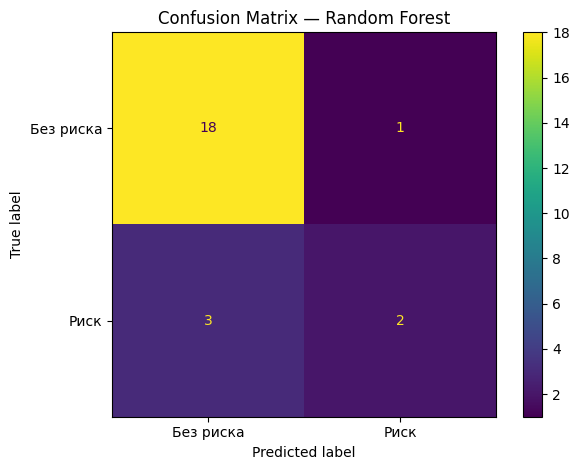

Confusion matrix сохранена: c:\Diplom_Suslikov_2026\diabetes-risk-stratifier\results\figures\confusion_matrix_random_forest.png


In [11]:
cm = confusion_matrix(y_test, rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Без риска", "Риск"]
)

disp.plot()
plt.title("Confusion Matrix — Random Forest")
plt.tight_layout()

confusion_matrix_path = RESULTS_FIGURES_DIR / "confusion_matrix_random_forest.png"
plt.savefig(confusion_matrix_path, dpi=300)
plt.show()

print("Confusion matrix сохранена:", confusion_matrix_path)

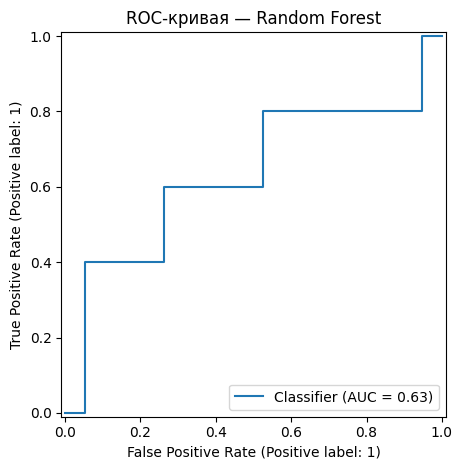

ROC-кривая сохранена: c:\Diplom_Suslikov_2026\diabetes-risk-stratifier\results\figures\roc_curve_random_forest.png


In [12]:
RocCurveDisplay.from_predictions(y_test, rf_proba)
plt.title("ROC-кривая — Random Forest")
plt.tight_layout()

roc_curve_path = RESULTS_FIGURES_DIR / "roc_curve_random_forest.png"
plt.savefig(roc_curve_path, dpi=300)
plt.show()

print("ROC-кривая сохранена:", roc_curve_path)

In [13]:
rf_classifier = random_forest_model.named_steps["classifier"]

feature_importance = pd.DataFrame({
    "feature": feature_cols,
    "importance": rf_classifier.feature_importances_
}).sort_values("importance", ascending=False)

feature_importance.head(15)

,feature,importance
3,diabetes_duration_last,0.123395
4,diabetes_duration_max,0.104667
5,hba1c_mean,0.073177
15,triglycerides_last,0.068706
14,triglycerides_mean,0.056968
16,total_cholesterol_mean,0.052038
10,ldl_mean,0.046698
6,hba1c_last,0.046616
11,ldl_last,0.040646
7,hba1c_max,0.039575


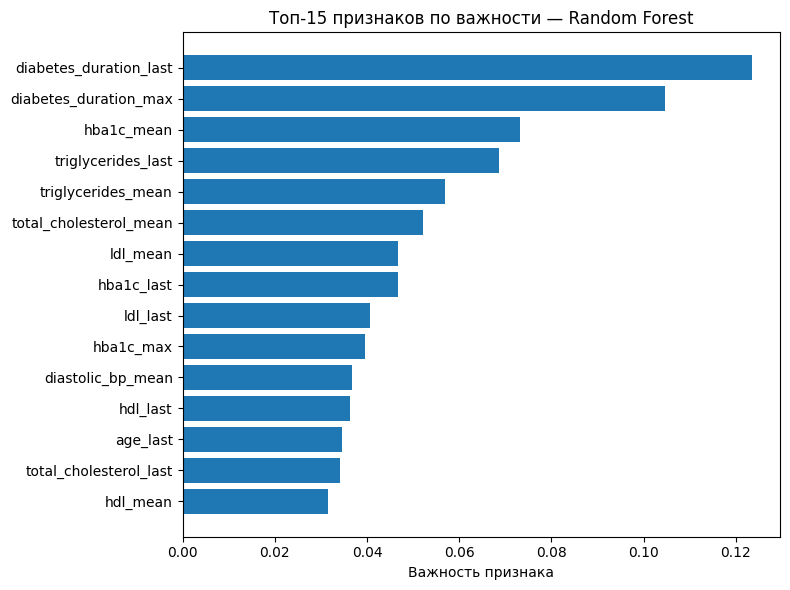

График важности признаков сохранён: c:\Diplom_Suslikov_2026\diabetes-risk-stratifier\results\figures\feature_importance_random_forest.png


In [14]:
top_features = feature_importance.head(15).sort_values("importance", ascending=True)

plt.figure(figsize=(8, 6))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("Важность признака")
plt.title("Топ-15 признаков по важности — Random Forest")
plt.tight_layout()

feature_importance_path = RESULTS_FIGURES_DIR / "feature_importance_random_forest.png"
plt.savefig(feature_importance_path, dpi=300)
plt.show()

print("График важности признаков сохранён:", feature_importance_path)

In [15]:
if rf_metrics["f1_score"] >= logistic_metrics["f1_score"]:
    best_model_name = "Random Forest"
    best_model = random_forest_model
    best_metrics = rf_metrics
else:
    best_model_name = "Logistic Regression"
    best_model = logistic_model
    best_metrics = logistic_metrics

print("Выбранная модель:", best_model_name)
print("Метрики выбранной модели:")
for key, value in best_metrics.items():
    if key != "model":
        print(f"{key}: {value:.3f}")

Выбранная модель: Random Forest
Метрики выбранной модели:
accuracy: 0.833
precision: 0.667
recall: 0.400
f1_score: 0.500
roc_auc: 0.632


In [16]:
model_path = MODELS_DIR / "nephropathy_model.joblib"
features_path = MODELS_DIR / "feature_columns.json"
metadata_path = MODELS_DIR / "model_metadata.json"

joblib.dump(best_model, model_path)

with open(features_path, "w", encoding="utf-8") as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=4)

metadata = {
    "model_name": best_model_name,
    "target": "nephropathy_risk",
    "risk_levels": {
        "low": "0-30%",
        "moderate": "31-70%",
        "high": "71-100%"
    },
    "metrics": {
        key: float(value)
        for key, value in best_metrics.items()
        if key != "model"
    }
}

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)

print("Модель сохранена:", model_path)
print("Список признаков сохранён:", features_path)
print("Метаданные модели сохранены:", metadata_path)

Модель сохранена: c:\Diplom_Suslikov_2026\diabetes-risk-stratifier\models\nephropathy_model.joblib
Список признаков сохранён: c:\Diplom_Suslikov_2026\diabetes-risk-stratifier\models\feature_columns.json
Метаданные модели сохранены: c:\Diplom_Suslikov_2026\diabetes-risk-stratifier\models\model_metadata.json


# Улучшение модели: подбор параметров и порога классификации

In [17]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score

In [18]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

In [19]:
rf_pipeline_for_search = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            random_state=42,
            class_weight="balanced"
        )),
    ]
)

In [20]:
param_grid = {
    "classifier__n_estimators": [100, 200, 500],
    "classifier__max_depth": [2, 3, 4, 5, None],
    "classifier__min_samples_leaf": [1, 2, 3, 5],
    "classifier__max_features": ["sqrt", "log2"],
    "classifier__class_weight": ["balanced", "balanced_subsample"],
}

param_grid

{'classifier__n_estimators': [100, 200, 500],
 'classifier__max_depth': [2, 3, 4, 5, None],
 'classifier__min_samples_leaf': [1, 2, 3, 5],
 'classifier__max_features': ['sqrt', 'log2'],
 'classifier__class_weight': ['balanced', 'balanced_subsample']}

In [21]:
rf_grid_search = GridSearchCV(
    estimator=rf_pipeline_for_search,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

rf_grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 240 candidates, totalling 1200 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__class_weight': ['balanced', 'balanced_subsample'], 'classifier__max_depth': [2, 3, ...], 'classifier__max_features': ['sqrt', 'log2'], 'classifier__min_samples_leaf': [1, 2, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intContr

In [22]:
print("Лучшие параметры:")
print(rf_grid_search.best_params_)

print("\nЛучший средний F1-score на кросс-валидации:")
print(round(rf_grid_search.best_score_, 3))

Лучшие параметры:
{'classifier__class_weight': 'balanced', 'classifier__max_depth': 2, 'classifier__max_features': 'log2', 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 200}

Лучший средний F1-score на кросс-валидации:
0.383


In [23]:
tuned_rf_model = rf_grid_search.best_estimator_

tuned_rf_metrics_05, tuned_rf_pred_05, tuned_rf_proba = evaluate_model(
    "Random Forest Tuned threshold=0.50",
    tuned_rf_model,
    X_test,
    y_test
)


=== Random Forest Tuned threshold=0.50 ===
Метрики:
accuracy: 0.750
precision: 0.400
recall: 0.400
f1_score: 0.400
roc_auc: 0.684

Classification report:
              precision    recall  f1-score   support

           0       0.84      0.84      0.84        19
           1       0.40      0.40      0.40         5

    accuracy                           0.75        24
   macro avg       0.62      0.62      0.62        24
weighted avg       0.75      0.75      0.75        24



In [24]:
def evaluate_with_threshold(model_name, y_true, y_proba, threshold):
    """
    Оценивает модель при заданном пороге вероятности.
    """
    y_pred = (y_proba >= threshold).astype(int)

    metrics = {
        "model": model_name,
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1_score": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba),
    }

    return metrics

In [25]:
thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:
    metrics = evaluate_with_threshold(
        model_name="Random Forest Tuned",
        y_true=y_test,
        y_proba=tuned_rf_proba,
        threshold=threshold
    )
    threshold_results.append(metrics)

threshold_results_df = pd.DataFrame(threshold_results)

threshold_results_df_rounded = threshold_results_df.copy()
for col in ["threshold", "accuracy", "balanced_accuracy", "precision", "recall", "f1_score", "roc_auc"]:
    threshold_results_df_rounded[col] = threshold_results_df_rounded[col].round(3)

threshold_results_df_rounded

,model,threshold,accuracy,balanced_accuracy,precision,recall,f1_score,roc_auc
0,Random Forest Tuned,0.10,0.208,0.500,0.208,1.0,0.345,0.684
1,Random Forest Tuned,0.15,0.208,0.500,0.208,1.0,0.345,0.684
2,Random Forest Tuned,0.20,0.250,0.526,0.217,1.0,0.357,0.684
3,Random Forest Tuned,0.25,0.292,0.553,0.227,1.0,0.370,0.684
4,Random Forest Tuned,0.30,0.375,0.532,0.222,0.8,0.348,0.684
5,Random Forest Tuned,0.35,0.500,0.611,0.267,0.8,0.400,0.684
6,Random Forest Tuned,0.40,0.667,0.642,0.333,0.6,0.429,0.684
7,Random Forest Tuned,0.45,0.625,0.542,0.250,0.4,0.308,0.684
8,Random Forest Tuned,0.50,0.750,0.621,0.400,0.4,0.400,0.684
9,Random Forest Tuned,0.55,0.792,0.574,0.500,0.2,0.286,0.684


In [27]:
# Сначала попробуем выбрать порог, где recall хотя бы 0.60.
# Это значит: модель должна находить хотя бы 60% пациентов с риском.

min_required_recall = 0.60

valid_thresholds = threshold_results_df[
    threshold_results_df["recall"] >= min_required_recall
].copy()

if len(valid_thresholds) > 0:
    best_threshold_row = valid_thresholds.sort_values(
        ["f1_score", "balanced_accuracy"],
        ascending=False
    ).iloc[0]
else:
    # Если таких порогов нет, выбираем просто максимальный F1-score.
    best_threshold_row = threshold_results_df.sort_values(
        ["f1_score", "balanced_accuracy"],
        ascending=False
    ).iloc[0]

best_threshold = float(best_threshold_row["threshold"])

print("Выбранный порог:", round(best_threshold, 2))
print("\nМетрики при выбранном пороге:")

# Красиво выводим только числовые метрики
display(
    pd.DataFrame([best_threshold_row]).round({
        "threshold": 3,
        "accuracy": 3,
        "balanced_accuracy": 3,
        "precision": 3,
        "recall": 3,
        "f1_score": 3,
        "roc_auc": 3,
    })
)

Выбранный порог: 0.4

Метрики при выбранном пороге:


,model,threshold,accuracy,balanced_accuracy,precision,recall,f1_score,roc_auc
6,Random Forest Tuned,0.4,0.667,0.642,0.333,0.6,0.429,0.684


In [28]:
tuned_rf_final_pred = (tuned_rf_proba >= best_threshold).astype(int)

tuned_rf_final_metrics = {
    "model": "Random Forest Tuned",
    "threshold": best_threshold,
    "accuracy": accuracy_score(y_test, tuned_rf_final_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, tuned_rf_final_pred),
    "precision": precision_score(y_test, tuned_rf_final_pred, zero_division=0),
    "recall": recall_score(y_test, tuned_rf_final_pred, zero_division=0),
    "f1_score": f1_score(y_test, tuned_rf_final_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, tuned_rf_proba),
}

print("Финальные метрики улучшенной модели:")
for key, value in tuned_rf_final_metrics.items():
    if key == "model":
        print(f"{key}: {value}")
    else:
        print(f"{key}: {value:.3f}")

Финальные метрики улучшенной модели:
model: Random Forest Tuned
threshold: 0.400
accuracy: 0.667
balanced_accuracy: 0.642
precision: 0.333
recall: 0.600
f1_score: 0.429
roc_auc: 0.684


In [29]:
all_metrics = []

# Старая логистическая регрессия
logistic_metrics_extended = logistic_metrics.copy()
logistic_metrics_extended["threshold"] = 0.50
logistic_metrics_extended["balanced_accuracy"] = balanced_accuracy_score(y_test, logistic_pred)

# Старый Random Forest
rf_metrics_extended = rf_metrics.copy()
rf_metrics_extended["threshold"] = 0.50
rf_metrics_extended["balanced_accuracy"] = balanced_accuracy_score(y_test, rf_pred)

all_metrics.append(logistic_metrics_extended)
all_metrics.append(rf_metrics_extended)
all_metrics.append(tuned_rf_final_metrics)

final_comparison_df = pd.DataFrame(all_metrics)

# Упорядочим столбцы
final_comparison_df = final_comparison_df[
    [
        "model",
        "threshold",
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1_score",
        "roc_auc",
    ]
]

final_comparison_rounded = final_comparison_df.copy()

for col in ["threshold", "accuracy", "balanced_accuracy", "precision", "recall", "f1_score", "roc_auc"]:
    final_comparison_rounded[col] = final_comparison_rounded[col].round(3)

final_comparison_rounded

,model,threshold,accuracy,balanced_accuracy,precision,recall,f1_score,roc_auc
0,Logistic Regression,0.5,0.583,0.442,0.143,0.2,0.167,0.316
1,Random Forest,0.5,0.833,0.674,0.667,0.4,0.500,0.632
2,Random Forest Tuned,0.4,0.667,0.642,0.333,0.6,0.429,0.684


In [30]:
final_metrics_path = RESULTS_METRICS_DIR / "final_model_comparison.csv"

final_comparison_rounded.to_csv(
    final_metrics_path,
    index=False,
    encoding="utf-8-sig"
)

print("Финальная таблица метрик сохранена:", final_metrics_path)

Финальная таблица метрик сохранена: c:\Diplom_Suslikov_2026\diabetes-risk-stratifier\results\metrics\final_model_comparison.csv


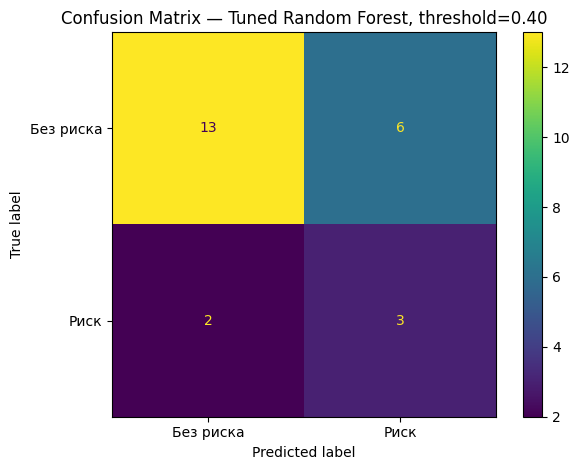

Confusion matrix улучшенной модели сохранена: c:\Diplom_Suslikov_2026\diabetes-risk-stratifier\results\figures\confusion_matrix_tuned_random_forest.png


In [31]:
cm_tuned = confusion_matrix(y_test, tuned_rf_final_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=["Без риска", "Риск"]
)

disp.plot()
plt.title(f"Confusion Matrix — Tuned Random Forest, threshold={best_threshold:.2f}")
plt.tight_layout()

confusion_matrix_tuned_path = RESULTS_FIGURES_DIR / "confusion_matrix_tuned_random_forest.png"
plt.savefig(confusion_matrix_tuned_path, dpi=300)
plt.show()

print("Confusion matrix улучшенной модели сохранена:", confusion_matrix_tuned_path)

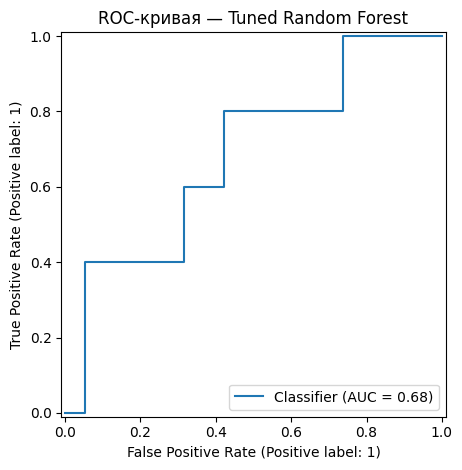

ROC-кривая улучшенной модели сохранена: c:\Diplom_Suslikov_2026\diabetes-risk-stratifier\results\figures\roc_curve_tuned_random_forest.png


In [32]:
RocCurveDisplay.from_predictions(y_test, tuned_rf_proba)
plt.title("ROC-кривая — Tuned Random Forest")
plt.tight_layout()

roc_curve_tuned_path = RESULTS_FIGURES_DIR / "roc_curve_tuned_random_forest.png"
plt.savefig(roc_curve_tuned_path, dpi=300)
plt.show()

print("ROC-кривая улучшенной модели сохранена:", roc_curve_tuned_path)

In [33]:
tuned_rf_classifier = tuned_rf_model.named_steps["classifier"]

tuned_feature_importance = pd.DataFrame({
    "feature": feature_cols,
    "importance": tuned_rf_classifier.feature_importances_
}).sort_values("importance", ascending=False)

tuned_feature_importance.head(15)

,feature,importance
3,diabetes_duration_last,0.141570
4,diabetes_duration_max,0.109782
5,hba1c_mean,0.076875
15,triglycerides_last,0.068420
6,hba1c_last,0.058535
14,triglycerides_mean,0.058100
7,hba1c_max,0.049614
16,total_cholesterol_mean,0.047477
20,diastolic_bp_mean,0.038628
18,systolic_bp_mean,0.035152


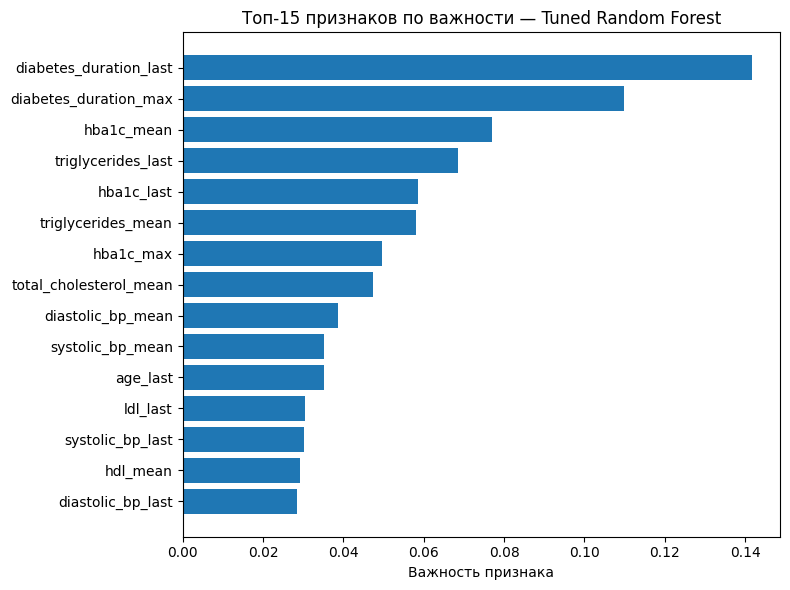

График важности признаков улучшенной модели сохранён: c:\Diplom_Suslikov_2026\diabetes-risk-stratifier\results\figures\feature_importance_tuned_random_forest.png


In [34]:
top_tuned_features = tuned_feature_importance.head(15).sort_values("importance", ascending=True)

plt.figure(figsize=(8, 6))
plt.barh(top_tuned_features["feature"], top_tuned_features["importance"])
plt.xlabel("Важность признака")
plt.title("Топ-15 признаков по важности — Tuned Random Forest")
plt.tight_layout()

feature_importance_tuned_path = RESULTS_FIGURES_DIR / "feature_importance_tuned_random_forest.png"
plt.savefig(feature_importance_tuned_path, dpi=300)
plt.show()

print("График важности признаков улучшенной модели сохранён:", feature_importance_tuned_path)

In [ ]:
model_path = MODELS_DIR / "nephropathy_model.joblib"
features_path = MODELS_DIR / "feature_columns.json"
metadata_path = MODELS_DIR / "model_metadata.json"

joblib.dump(tuned_rf_model, model_path)

with open(features_path, "w", encoding="utf-8") as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=4)

metadata = {
    "model_name": "Random Forest Tuned",
    "target": "nephropathy_risk",
    "decision_threshold": best_threshold,
    "risk_levels": {
        "low": "0-30%",
        "moderate": "31-70%",
        "high": "71-100%"
    },
    "metrics": {
        key: float(value)
        for key, value in tuned_rf_final_metrics.items()
        if key != "model"
    },
    "note": (
        "Модель обучена на агрегированных данных: один пациент = одна строка. "
        "ACR, альбуминурия и СКФ не использовались как входные признаки, "
        "так как применялись для формирования целевой переменной nephropathy_risk."
    )
}

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)

print("Улучшенная модель сохранена:", model_path)
print("Список признаков сохранён:", features_path)
print("Метаданные модели сохранены:", metadata_path)

Улучшенная модель сохранена: c:\Diplom_Suslikov_2026\diabetes-risk-stratifier\models\nephropathy_model.joblib
Список признаков сохранён: c:\Diplom_Suslikov_2026\diabetes-risk-stratifier\models\feature_columns.json
Метаданные модели сохранены: c:\Diplom_Suslikov_2026\diabetes-risk-stratifier\models\model_metadata.json


# Обучение модели риска диабетической ретинопатии / ангиопатии

In [ ]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)

In [ ]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

MODEL_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "model_dataset.csv"

model_df = pd.read_csv(MODEL_DATA_PATH)

print("Размер датасета:", model_df.shape)
print("Столбцы:")
for col in model_df.columns:
    print(col)

TARGET = "angiopathy_risk"

print("\nРаспределение целевой переменной angiopathy_risk:")
print(model_df[TARGET].value_counts(dropna=False))